# 05 · Tokenization: word-level vs BPE

Point 5 of `PLAN.md` (owner: Ivan). Does splitting words into **BPE subwords** beat a **word-level** vocabulary for
location tagging? And where should a word's label go when the word is split into several pieces?

**Why it matters (from notebook 01):** 28% of the words inside gold locations are missing from a 50k word
vocabulary. Unseen town names (`Фастів`, `Хелма`) and inflected forms (`Васильковом`, `Київщині`) all become the same
`<unk>` token, so the model has to guess them from context alone.

**Earlier attempt:** a *unidirectional* vanilla RNN with BPE and the label on the first subtoken scored CV 0.411,
against 0.500 for word-level. The label of `Васильковом` was predicted at `василь`, before the model had read the
rest of the word. This notebook therefore crosses **tokenizer × label alignment × direction**:

| | label on first subtoken | label on last subtoken |
|---|---|---|
| **unidirectional GRU** | predicts before seeing the word's end | sees the whole word |
| **BiGRU** | sees the whole word through the backward pass | sees the whole word |

All runs share everything else: data, splits, model size, optimizer, epochs and seed. The architecture is a
reasonable default (1-layer GRU, 256 hidden). Mykola's point 3 picks the best one later.

**How to run:** on Colab with a T4, top to bottom. The full set of runs takes about 1–1.5 hours. Set the environment
variable `QUICK_RUN=1` to check the code on a small subset in a few minutes, on CPU.

In [ ]:
NOTEBOOK = "05-tokenization"  # W&B group of this notebook's runs

## 0. Shared code
Section 0 is **identical in every model notebook**, so all of them use the same splits, metric, tokenizer, training
loop and output format. The master copy is in notebook 02: change it there first, then paste it into the others.
Code specific to one notebook (a new model, a new tokenizer) goes in that notebook's own sections.

### 0.0 Setup
- **Colab:** upload `secrets.env` (`KAGGLE_USERNAME`, `KAGGLE_KEY`, `WANDB_API_KEY`) to `/content/` first. The cell
  loads the keys (it prints only their names), installs missing packages, and downloads the data with the Kaggle CLI.
  If Google Drive is mounted at `/content/drive`, run outputs go to `MyDrive/dl-a3-artifacts` so they survive the VM
  reset. Make that folder a shortcut to the team's shared folder, so everyone writes to the same results log.
- **Locally:** the data is read from `data/raw/`, outputs go to `artifacts/` (git-ignored).
- `QUICK_RUN=1` (environment variable) trains on a small subset for one epoch, to check the code in a few minutes.

In [ ]:
import importlib.util
import os
import shutil
import subprocess
import sys
from pathlib import Path

COMPETITION = "kse-ua-location-extraction-2026"
DATA_FILES = ["uk_geo_dataset.csv", "labeling_sample.csv", "test.csv"]
IN_COLAB = Path("/content").exists()
QUICK_RUN = os.environ.get("QUICK_RUN") == "1"


def load_secrets(path: Path = Path("/content/secrets.env")) -> None:
    assert path.exists(), f"Upload secrets.env to {path.parent} first"
    for line in path.read_text().splitlines():
        if "=" in line and not line.lstrip().startswith("#"):
            key, value = line.split("=", 1)
            os.environ[key.strip()] = value.strip()
    print("keys loaded:", [k for k in ("KAGGLE_USERNAME", "KAGGLE_KEY", "WANDB_API_KEY") if os.environ.get(k)])


def download_data(raw: Path) -> None:
    raw.mkdir(parents=True, exist_ok=True)
    for name in DATA_FILES:
        if (raw / name).exists():
            continue
        subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-f", name, "-p", str(raw)], check=True)
        archive = raw / f"{name}.zip"
        if archive.exists():  # large files arrive zipped
            shutil.unpack_archive(archive, raw)
            archive.unlink()


def install_missing(packages: dict[str, str]) -> None:
    """{import name: pip name}; installs only what is missing."""
    missing = [pip for module, pip in packages.items() if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)


install_missing({"lightning": "lightning", "tokenizers": "tokenizers", "wandb": "wandb", "kaggle": "kaggle"})
if IN_COLAB:
    load_secrets()
    RAW = Path("/content/data/raw")
    download_data(RAW)
    drive = Path("/content/drive/MyDrive")
    ARTIFACTS = (drive / "dl-a3-artifacts") if drive.exists() else Path("/content/artifacts")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    RAW, ARTIFACTS = ROOT / "data/raw", ROOT / "artifacts"
if QUICK_RUN:
    ARTIFACTS = ARTIFACTS / "quick_run"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print(f"data: {RAW} | outputs: {ARTIFACTS} | quick run: {QUICK_RUN}")

keys loaded: ['KAGGLE_USERNAME', 'KAGGLE_KEY', 'WANDB_API_KEY']
data: /content/data/raw | outputs: /content/artifacts | quick run: False


### 0.1 Tokenizer, span ↔ BIO, competition metric
Every training notebook uses the same code. Each token keeps its character offsets, so predicted tags can be turned
back into **exact substrings** of the text, which is what the metric compares. Punctuation becomes its own token
(`Київ,` → `Київ` `,`), while inner hyphens and apostrophes stay inside the word (`Івано-Франківськ`,
`Слов'янськ`).

In [ ]:
import ast
import re
import string
from collections import Counter
from dataclasses import dataclass
from typing import List, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

TOKEN_RE = re.compile(r"\w+(?:[-'’ʼ`]\w+)*|[^\w\s]")


@dataclass(frozen=True)
class Token:
    text: str
    start: int
    end: int  # exclusive


def word_tokenize(text: str) -> list[Token]:
    return [Token(m.group(), m.start(), m.end()) for m in TOKEN_RE.finditer(text)]


def parse_markers(value) -> list[tuple[int, int]]:
    """`loc_markers` as stored in the CSV ("[(0, 4), (10, 15)]") -> [(start, end), ...], end exclusive."""
    if not isinstance(value, str):
        return []
    return [(int(a), int(b)) for a, b in ast.literal_eval(value.strip() or "[]")]


def spans_to_bio(tokens: Sequence[Token], spans) -> list[str]:
    """Every token that overlaps a span is labelled: the first one B-LOC, the rest I-LOC."""
    labels = ["O"] * len(tokens)
    for left, right in sorted(spans):
        first = True
        for i, tok in enumerate(tokens):
            if tok.start < right and tok.end > left:
                labels[i] = "B-LOC" if first else "I-LOC"
                first = False
    return labels


def bio_to_spans(tokens: Sequence[Token], tags: Sequence[str]) -> list[tuple[int, int]]:
    """Merge BIO tags into character spans; an I-LOC without an open entity starts a new one."""
    spans, current = [], None
    for tok, tag in zip(tokens, tags):
        if tag == "B-LOC" or (tag == "I-LOC" and current is None):
            if current is not None:
                spans.append(tuple(current))
            current = [tok.start, tok.end]
        elif tag == "I-LOC":
            current[1] = tok.end
        else:
            if current is not None:
                spans.append(tuple(current))
            current = None
    if current is not None:
        spans.append(tuple(current))
    return spans


def spans_to_strings(text: str, spans) -> list[str]:
    """Cut location strings out of the original text (deduplicated, order kept)."""
    return list(dict.fromkeys(s for s in (text[a:b].strip() for a, b in spans) if s))

`hard_processing` and `comp_metric` below are copied **verbatim** from the competition page. Do not "fix" them.

In [ ]:
def hard_processing(text):
    text = re.sub(r"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\d', '', text)
    text = re.sub(r'\b\w\b\s?', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()


def comp_metric(y_true: List[List[str]], y_pred: List[List[str]]):
    assert len(y_true) == len(y_pred)
    tp, fp, fn, p,  = 0.0, 0.0, 0.0, 0.0

    for y_true_sample, y_pred_sample in zip(y_true, y_pred):
        y_true_sample = set([hard_processing(s) for s in y_true_sample])
        y_pred_sample = set([hard_processing(s) for s in y_pred_sample])

        tp += len(y_true_sample & y_pred_sample)
        fp += len(y_pred_sample - y_true_sample)
        fn += len(y_true_sample - y_pred_sample)
        p += len(y_true_sample)

    if tp + fp == 0:
        if p == 0:
            precision = 1.0
        else:
            precision = 0.0
    else:
        precision = tp/(tp + fp)

    if tp + fn == 0:
        if p == 0:
            recall = 1.0
        else:
            recall = 0.0
    else:
        recall = tp/(tp + fn)

    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return round(f1, 8)

Complementary metrics (notebook 01, section 8). They count exactly like `comp_metric`, plus:

In [ ]:
def precision_recall(y_true, y_pred) -> tuple[float, float]:
    tp = fp = fn = 0
    for t_s, p_s in zip(y_true, y_pred):
        t, p = {hard_processing(s) for s in t_s}, {hard_processing(s) for s in p_s}
        tp, fp, fn = tp + len(t & p), fp + len(p - t), fn + len(t - p)
    precision = tp / (tp + fp) if tp + fp else float(tp + fn == 0)
    recall = tp / (tp + fn) if tp + fn else 1.0
    return precision, recall


def partial_match_f1(y_true, y_pred) -> float:
    """Boundary-tolerant F1: a location counts if it shares a normalized word with one on the other side."""
    words = lambda s: set(hard_processing(s).split())
    hit_p = n_p = hit_t = n_t = 0
    for t_s, p_s in zip(y_true, y_pred):
        t_sets = [words(s) for s in {hard_processing(x) for x in t_s}]
        p_sets = [words(s) for s in {hard_processing(x) for x in p_s}]
        n_p, n_t = n_p + len(p_sets), n_t + len(t_sets)
        hit_p += sum(any(p & t for t in t_sets) for p in p_sets)
        hit_t += sum(any(t & p for p in p_sets) for t in t_sets)
    precision, recall = (hit_p / n_p if n_p else 1.0), (hit_t / n_t if n_t else 1.0)
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0


def metric_report(y_true, y_pred) -> dict:
    precision, recall = precision_recall(y_true, y_pred)
    no_loc = [len(p) > 0 for t, p in zip(y_true, y_pred) if not t]
    with_loc = [(t, p) for t, p in zip(y_true, y_pred) if t]
    return {
        "comp_f1": comp_metric(y_true, y_pred),
        "precision": precision,
        "recall": recall,
        "partial_f1": partial_match_f1(y_true, y_pred),
        "f1_texts_with_loc": comp_metric([t for t, _ in with_loc], [p for _, p in with_loc]),
        "fp_rate_texts_without_loc": float(np.mean(no_loc)) if no_loc else 0.0,
    }


def bootstrap_ci(y_true, y_pred, n_boot: int = 2000, seed: int = 0, alpha: float = 0.05) -> tuple[float, float]:
    """95% interval of comp_metric when the texts are resampled with replacement (CV has only 26 texts)."""
    rng, n = np.random.default_rng(seed), len(y_true)
    scores = [comp_metric([y_true[i] for i in idx], [y_pred[i] for i in idx]) for idx in rng.integers(0, n, (n_boot, n))]
    low, high = np.quantile(scores, [alpha / 2, 1 - alpha / 2])
    return float(low), float(high)

### 0.2 Data: corpora and encoded datasets
- A `Corpus` holds the texts, word tokens and BIO tags (label ids) of one split, and the gold strings. For
  evaluation splits it also keeps the tokens with their offsets, which decoding needs (train skips them to save
  memory).
- A **vocabulary** maps words to ids. Any vocabulary works if it has
  `encode_batch(word_lists) -> [(ids, first_pos, last_pos), ...]`, where `first_pos[w]` and `last_pos[w]` are the
  positions of word `w`'s first and last id. For word-level they are equal. For BPE a word can have several pieces.
- `EncodedDataset` puts each word's label on its first or last piece (`alignment`). Every other position gets −100,
  which the loss ignores (same idea as `DataCollatorForTokenClassification` in the lecture). Training sequences are cut
  at `max_len` ids. Evaluation sequences are **never cut**, because test posts can be long (notebook 01).

In [ ]:
import json
import logging
import time
import warnings
from collections import Counter

import lightning as L
import torch
import torch.nn as nn
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger, WandbLogger
from lightning.pytorch.utilities import grad_norm
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore", module="lightning")
logging.getLogger("lightning.pytorch").setLevel(logging.WARNING)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LABELS = ["O", "B-LOC", "I-LOC"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))
PAD_TOKEN, UNK_TOKEN, PAD_ID, UNK_ID, IGNORE_INDEX = "<pad>", "<unk>", 0, 1, -100
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")


class Corpus:
    def __init__(self, texts, spans=None, keep_tokens: bool = True):
        texts = [str(t) for t in texts]
        tokens = [word_tokenize(t) for t in texts]
        self.words = [[t.text for t in toks] for toks in tokens]
        self.tags = None if spans is None else [
            np.array([LABEL2ID[tag] for tag in spans_to_bio(toks, s)], dtype=np.int64) for toks, s in zip(tokens, spans)]
        self.gold = None if spans is None else [[t[a:b] for a, b in s] for t, s in zip(texts, spans)]
        self.texts, self.tokens = texts, (tokens if keep_tokens else None)

    def __len__(self) -> int:
        return len(self.words)


class WordVocab:
    """Word -> id, built on training words only; the `max_size` most frequent words seen `min_freq`+ times; the rest
    -> <unk>. `lowercase=False` keeps case (`Київ` and `київ` become different words)."""

    def __init__(self, word_lists, max_size: int = 50_000, min_freq: int = 2, lowercase: bool = True):
        self.norm = str.lower if lowercase else str
        counts = Counter(self.norm(w) for words in word_lists for w in words)
        self.itos = [PAD_TOKEN, UNK_TOKEN] + [w for w, c in counts.most_common(max_size - 2) if c >= min_freq]
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    def __len__(self) -> int:
        return len(self.itos)

    def encode_batch(self, word_lists):
        for words in word_lists:
            ids = [self.stoi.get(self.norm(w), UNK_ID) for w in words]
            positions = list(range(len(words)))
            yield ids, positions, positions


class EncodedDataset(Dataset):
    def __init__(self, corpus: Corpus, vocab, alignment: str = "first", max_len: int | None = None):
        assert alignment in ("first", "last")
        self.items = []
        for i, (ids, first, last) in enumerate(vocab.encode_batch(corpus.words)):
            ids, pos = np.asarray(ids, dtype=np.int64), np.asarray(first if alignment == "first" else last, dtype=np.int64)
            labels = np.full(len(ids), IGNORE_INDEX, dtype=np.int64)
            if corpus.tags is not None:
                labels[pos] = corpus.tags[i]
            if max_len is not None and len(ids) > max_len:
                ids, labels, pos = ids[:max_len], labels[:max_len], pos[pos < max_len]
            self.items.append((ids, labels, pos))

    def __len__(self) -> int:
        return len(self.items)

    def __getitem__(self, idx: int):
        return (idx, *self.items[idx])


def collate(batch) -> dict:
    """Right-pad ids with PAD_ID and labels with −100; `lengths` feed pack_padded_sequence."""
    lengths = torch.tensor([max(len(ids), 1) for _, ids, _, _ in batch])
    input_ids = torch.full((len(batch), int(lengths.max())), PAD_ID, dtype=torch.long)
    labels = torch.full_like(input_ids, IGNORE_INDEX)
    for row, (_, ids, lab, _) in enumerate(batch):
        input_ids[row, :len(ids)] = torch.from_numpy(ids)
        labels[row, :len(lab)] = torch.from_numpy(lab)
    return {"idx": [b[0] for b in batch], "input_ids": input_ids, "labels": labels, "lengths": lengths,
            "positions": [b[3] for b in batch]}

device: cuda Tesla T4


**Splits** (point 2.1, motivated in notebook 02). They are fixed by the data, so they need no seed:
- **train** = `uk_geo_dataset` with `is_valid==0` (1M sentences);
- **es** = `is_valid==1` (10k sentences, train domain): early stopping and checkpoint choice;
- **CV** = `labeling_sample` (26 test-like texts): the score we report and compare with the LB;
- **test** = 477 posts for the submission.

`QUICK_RUN` samples 20k train and 2k es sentences with a fixed seed.

In [ ]:
def load_corpora() -> tuple[dict[str, Corpus], pd.DataFrame]:
    uk = pd.read_csv(RAW / "uk_geo_dataset.csv", usecols=["text", "loc_markers", "is_valid"])
    ls = pd.read_csv(RAW / "labeling_sample.csv")
    test = pd.read_csv(RAW / "test.csv")
    train_df, es_df = uk[uk.is_valid == 0], uk[uk.is_valid == 1]
    if QUICK_RUN:
        train_df, es_df = train_df.sample(20_000, random_state=0), es_df.sample(2_000, random_state=0)
    corpora = {
        "train": Corpus(train_df.text, train_df.loc_markers.map(parse_markers), keep_tokens=False),
        "es": Corpus(es_df.text, es_df.loc_markers.map(parse_markers)),
        "cv": Corpus(ls.text, ls.loc_markers.map(parse_markers)),
        "test": Corpus(test.text),
    }
    return corpora, test

### 0.3 Model
Embedding → GRU / LSTM / RNN (optionally bidirectional, several layers) → a linear layer on every position.
`pack_padded_sequence` makes the RNN stop at each text's real length, so padding never enters the hidden state, not
even in the backward direction.

In [ ]:
RNN_TYPES = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}


class RNNTagger(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int = 128, hidden_dim: int = 256, rnn_type: str = "gru",
                 num_layers: int = 1, bidirectional: bool = True, dropout: float = 0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.dropout = nn.Dropout(dropout)
        self.rnn = RNN_TYPES[rnn_type](embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                                       bidirectional=bidirectional, dropout=dropout if num_layers > 1 else 0.0)
        self.classifier = nn.Linear(hidden_dim * (2 if bidirectional else 1), len(LABELS))

    def forward(self, input_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        x = self.dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=input_ids.size(1))
        return self.classifier(self.dropout(out))  # [batch, time, labels]

### 0.4 Training and decoding
- Loss: token-level cross-entropy, ignoring −100.
- After every epoch, both validation sets are decoded to strings and scored with the **competition metric**:
  - `es_f1` (train domain) selects the checkpoint and drives early stopping;
  - `cv_f1` (test-like) is only reported. Choosing epochs on 26 CV texts would overfit them.
- Gradient norms per parameter (before clipping) are logged every `log_every_n_steps` steps: the gradient-flow
  check.
- Decoding: word-level probabilities → argmax tag per word → BIO → character spans → strings cut from the text.

In [ ]:
def word_probs(logits: torch.Tensor, positions) -> list[np.ndarray]:
    """[batch, time, labels] logits -> per text a [n_words, labels] probability array, read at the aligned piece."""
    probs = logits.float().softmax(-1).detach().cpu().numpy()
    return [probs[row, pos] for row, pos in enumerate(positions)]


def decode(corpus: Corpus, probs: list[np.ndarray]) -> list[list[str]]:
    tags = [[ID2LABEL[int(i)] for i in p.argmax(-1)] for p in probs]
    return [spans_to_strings(text, bio_to_spans(toks, t)) for text, toks, t in zip(corpus.texts, corpus.tokens, tags)]


class TaggerModule(L.LightningModule):
    def __init__(self, model: nn.Module, lr: float, weight_decay: float, val_corpora: dict[str, Corpus]):
        super().__init__()
        self.model, self.lr, self.weight_decay = model, lr, weight_decay
        self.val_names, self.val_corpora = list(val_corpora), list(val_corpora.values())
        self.loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)

    def _loss(self, logits, labels):
        return self.loss_fn(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))

    def training_step(self, batch, batch_idx):
        loss = self._loss(self.model(batch["input_ids"], batch["lengths"]), batch["labels"])
        self.log("train_loss", loss, on_step=True, on_epoch=True, batch_size=len(batch["idx"]))
        return loss

    def on_validation_epoch_start(self):
        self.val_probs = [{} for _ in self.val_names]

    def validation_step(self, batch, batch_idx, dataloader_idx=0):
        logits = self.model(batch["input_ids"], batch["lengths"])
        name = self.val_names[dataloader_idx]
        self.log(f"{name}_loss", self._loss(logits, batch["labels"]), batch_size=len(batch["idx"]),
                 add_dataloader_idx=False)
        self.val_probs[dataloader_idx].update(zip(batch["idx"], word_probs(logits, batch["positions"])))

    def on_validation_epoch_end(self):
        for name, corpus, buf in zip(self.val_names, self.val_corpora, self.val_probs):
            pred = decode(corpus, [buf[i] for i in range(len(corpus))])
            precision, recall = precision_recall(corpus.gold, pred)
            self.log_dict({f"{name}_f1": comp_metric(corpus.gold, pred), f"{name}_precision": precision,
                           f"{name}_recall": recall})

    def on_before_optimizer_step(self, optimizer):  # before clipping; Lightning writes it every log_every_n_steps
        self.log_dict(grad_norm(self.model, norm_type=2))

    def configure_optimizers(self):
        return torch.optim.AdamW(self.model.parameters(), lr=self.lr, weight_decay=self.weight_decay)


@torch.no_grad()
def predict(model: nn.Module, dataset: EncodedDataset, batch_size: int = 256) -> list[np.ndarray]:
    model.eval().to(DEVICE)
    out = [None] * len(dataset)
    for batch in DataLoader(dataset, batch_size=batch_size, collate_fn=collate):
        logits = model(batch["input_ids"].to(DEVICE), batch["lengths"])
        for i, p in zip(batch["idx"], word_probs(logits, batch["positions"])):
            out[i] = p
    return out

### 0.5 One experiment
`run_experiment(cfg, vocab, corpora, test_ids)`: train → reload the best checkpoint (by `es_f1`) → predict CV and test →
CV report → save outputs. If the run's `report.json` already exists it is loaded instead, so a crashed or
disconnected session can resume. Outputs in `ARTIFACTS/{run_name}/`:
- `best.ckpt` and `config.json`;
- `logs/metrics.csv` (curves);
- `cv_probs.pkl` and `test_probs.pkl` (word-level probabilities, for threshold tuning and ensembling);
- `submission.csv`;
- `report.json`.

In [ ]:
import pickle

WANDB_PROJECT = "kse-ua-location-extraction"


def save_probs(probs, path: Path) -> None:
    with open(path, "wb") as f:
        pickle.dump([p.astype(np.float16) for p in probs], f)


def load_probs(run: str, split: str) -> list[np.ndarray]:
    """Word-level probabilities a run saved for `split` ("cv" or "test")."""
    with open(ARTIFACTS / run / f"{split}_probs.pkl", "rb") as f:
        return [p.astype(np.float32) for p in pickle.load(f)]


def write_submission(text_ids, locations, path: Path) -> None:
    pd.DataFrame({"text_id": text_ids,
                  "locations": [json.dumps(list(x), ensure_ascii=False) for x in locations]}).to_csv(path, index=False)


def run_experiment(cfg: dict, vocab, corpora: dict[str, Corpus], test_ids, force: bool = False) -> dict:
    out = ARTIFACTS / cfg["run_name"]
    if (out / "report.json").exists() and not force:
        return json.loads((out / "report.json").read_text())
    out.mkdir(parents=True, exist_ok=True)
    (out / "config.json").write_text(json.dumps(cfg, indent=2))
    L.seed_everything(cfg["seed"], workers=True)
    start = time.time()

    encode = lambda name, max_len=None: EncodedDataset(corpora[name], vocab, cfg["alignment"], max_len)
    train_ds, es_ds, cv_ds, test_ds = encode("train", cfg["max_len"]), encode("es"), encode("cv"), encode("test")
    workers = 2 if DEVICE == "cuda" else 0
    loader = lambda ds, shuffle=False: DataLoader(ds, batch_size=cfg["batch_size"], shuffle=shuffle,
                                                  collate_fn=collate, num_workers=workers)

    model = RNNTagger(len(vocab), **cfg["model"])
    module = TaggerModule(model, cfg["lr"], cfg["weight_decay"], {"es": corpora["es"], "cv": corpora["cv"]})
    loggers = [CSVLogger(ARTIFACTS, name=cfg["run_name"], version="logs")]
    if os.environ.get("WANDB_API_KEY") and not QUICK_RUN:
        loggers.append(WandbLogger(project=WANDB_PROJECT, name=cfg["run_name"], group=NOTEBOOK, config=cfg,
                                   save_dir=str(out)))
    checkpoint = ModelCheckpoint(dirpath=out, filename="best", monitor="es_f1", mode="max", save_top_k=1)
    trainer = L.Trainer(max_epochs=cfg["max_epochs"], accelerator="gpu" if DEVICE == "cuda" else "cpu", devices=1,
                        gradient_clip_val=1.0, log_every_n_steps=10 if QUICK_RUN else 100, num_sanity_val_steps=0,
                        logger=loggers,
                        callbacks=[checkpoint, EarlyStopping(monitor="es_f1", mode="max", patience=cfg["patience"])],
                        enable_progress_bar=False, enable_model_summary=False)
    trainer.fit(module, loader(train_ds, shuffle=True), [loader(es_ds), loader(cv_ds)])

    best = torch.load(checkpoint.best_model_path, map_location="cpu", weights_only=False)
    model.load_state_dict({k.removeprefix("model."): v for k, v in best["state_dict"].items()})
    cv_probs, test_probs = predict(model, cv_ds), predict(model, test_ds)
    save_probs(cv_probs, out / "cv_probs.pkl")
    save_probs(test_probs, out / "test_probs.pkl")
    write_submission(test_ids, decode(corpora["test"], test_probs), out / "submission.csv")

    report = {"run_name": cfg["run_name"], **metric_report(corpora["cv"].gold, decode(corpora["cv"], cv_probs)),
              "es_f1": float(checkpoint.best_model_score), "best_epoch": int(best["epoch"]),
              "epochs_run": trainer.current_epoch, "vocab_size": len(vocab),
              "params": sum(p.numel() for p in model.parameters()), "minutes": (time.time() - start) / 60}
    (out / "report.json").write_text(json.dumps(report, indent=2))
    if len(loggers) > 1:
        loggers[1].experiment.summary.update({f"final_cv_{k}": v for k, v in report.items() if k != "run_name"})
        loggers[1].experiment.finish()
    return report

### 0.6 Results log and submissions
`ARTIFACTS/experiments.csv` holds one row per run: `run_name, owner, point, description, cv_f1, cv_p, cv_r, es_f1,
lb_public, notes`. Failed runs stay in. `log_result` replaces the run's row and keeps an LB score that is already
there. `submit` sends a run's `submission.csv` to Kaggle, waits for the public score, and writes it into the log.
The team has 10 submissions a day (Ivan 3, Mykola 4, Taras 3).

In [ ]:
import io

RESULTS_LOG = ARTIFACTS / "experiments.csv"
LOG_COLUMNS = ["run_name", "owner", "point", "description", "cv_f1", "cv_p", "cv_r", "es_f1", "lb_public", "notes"]


def read_log() -> pd.DataFrame:
    return pd.read_csv(RESULTS_LOG) if RESULTS_LOG.exists() else pd.DataFrame(columns=LOG_COLUMNS)


def log_result(cfg: dict, report: dict, lb_public: float | None = None, notes: str = "") -> pd.DataFrame:
    log = read_log()
    old = log[log.run_name == cfg["run_name"]]
    if lb_public is None and len(old):
        lb_public = old.lb_public.iloc[0]
    row = {"run_name": cfg["run_name"], "owner": cfg["owner"], "point": cfg["point"],
           "description": cfg.get("description", ""), "cv_f1": report["comp_f1"], "cv_p": report["precision"],
           "cv_r": report["recall"], "es_f1": report["es_f1"], "lb_public": lb_public, "notes": notes}
    others = log[log.run_name != cfg["run_name"]]
    log = pd.concat([others, pd.DataFrame([row])], ignore_index=True) if len(others) else pd.DataFrame([row])
    if not QUICK_RUN:
        log.to_csv(RESULTS_LOG, index=False)
    return log


def kaggle_public_score(message: str, timeout_s: int = 300) -> float | None:
    """Poll our Kaggle submissions until the one with this message has a public score."""
    for _ in range(timeout_s // 15):
        time.sleep(15)
        lines = subprocess.run(["kaggle", "competitions", "submissions", "-c", COMPETITION, "--csv"],
                               capture_output=True, text=True, check=True).stdout.splitlines()
        header = next(i for i, line in enumerate(lines) if "publicScore" in line)  # skip CLI warnings
        subs = pd.read_csv(io.StringIO("\n".join(lines[header:])))
        mine = subs[subs.description.astype(str) == message]
        if len(mine) and pd.notna(mine.publicScore.iloc[0]):  # newest first
            return float(mine.publicScore.iloc[0])
        if len(mine) and "error" in str(mine.status.iloc[0]).lower():
            raise RuntimeError(f"Kaggle rejected the submission: {mine.status.iloc[0]}")
    print("no public score yet; check Kaggle and call log_result(cfg, report, lb_public=...) by hand")
    return None


def submit(cfg: dict, report: dict, notes: str = "") -> float | None:
    path = ARTIFACTS / cfg["run_name"] / "submission.csv"
    message = f"{cfg['run_name']} | CV {report['comp_f1']:.3f}"
    subprocess.run(["kaggle", "competitions", "submit", "-c", COMPETITION, "-f", str(path), "-m", message], check=True)
    lb = kaggle_public_score(message)
    log_result(cfg, report, lb_public=lb, notes=notes)
    print(f"{cfg['run_name']}: public LB = {lb}")
    return lb

## 1. Data
The shared splits from section 0: train, es, CV and test.

In [ ]:
corpora, test = load_corpora()
print({name: len(c) for name, c in corpora.items()})

{'train': 1000000, 'es': 10000, 'cv': 26, 'test': 477}


## 2. BPE vocabularies
**BPE (byte-pair encoding)** starts from single characters and repeatedly merges the most frequent adjacent pair
into a new symbol, until the vocabulary has `vocab_size` entries. Frequent words end up as one piece. Rare words are
split into frequent pieces, so no word is ever `<unk>` unless it contains a character never seen in training.

Our setup (Hugging Face `tokenizers`):
- BPE is trained on the **words** produced by our word tokenizer, so a piece never crosses a word boundary and every
  piece belongs to exactly one word. This is what makes the label alignment possible.
- Text is lowercased, as in the word vocabulary, so the two differ only in how they split words.
- Pieces that continue a word get the prefix `##` (`васильковом` → `василь ##ков ##ом`). The model can tell a word
  start from its middle.
- Three sizes: 8k, 16k, 32k. Smaller means shorter pieces and longer sequences.

In [ ]:
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers


class BpeVocab:
    def __init__(self, word_lists, vocab_size: int, min_freq: int = 2):
        tok = Tokenizer(models.BPE(unk_token=UNK_TOKEN, continuing_subword_prefix="##"))
        tok.normalizer = normalizers.Lowercase()
        tok.pre_tokenizer = pre_tokenizers.WhitespaceSplit()  # our words contain no spaces
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=min_freq, show_progress=False,
                                      special_tokens=[PAD_TOKEN, UNK_TOKEN], continuing_subword_prefix="##")
        tok.train_from_iterator((" ".join(words) for words in word_lists), trainer)
        assert tok.token_to_id(PAD_TOKEN) == PAD_ID and tok.token_to_id(UNK_TOKEN) == UNK_ID
        self.tokenizer = tok

    def __len__(self) -> int:
        return self.tokenizer.get_vocab_size()

    def pieces(self, word: str) -> list[str]:
        return self.tokenizer.encode([word], is_pretokenized=True, add_special_tokens=False).tokens

    def encode_batch(self, word_lists, chunk_size: int = 10_000):
        for start in range(0, len(word_lists), chunk_size):
            chunk = word_lists[start:start + chunk_size]
            encodings = self.tokenizer.encode_batch([w or ["."] for w in chunk], is_pretokenized=True,
                                                    add_special_tokens=False)
            for words, enc in zip(chunk, encodings):
                if not words:
                    yield [], [], []
                    continue
                first, last = [None] * len(words), [None] * len(words)
                for pos, w in enumerate(enc.word_ids):
                    if first[w] is None:
                        first[w] = pos
                    last[w] = pos
                assert None not in first, "a word produced no pieces"
                yield enc.ids, first, last


start = time.time()
vocabs = {"word": WordVocab(corpora["train"].words)}
for size in (8_000, 16_000, 32_000):
    vocabs[f"bpe{size // 1000}k"] = BpeVocab(corpora["train"].words, vocab_size=size)
print({name: len(v) for name, v in vocabs.items()}, f"built in {time.time() - start:.0f}s")

{'word': 50000, 'bpe8k': 8000, 'bpe16k': 16000, 'bpe32k': 32000} built in 104s


In [ ]:
examples = ["Київ", "Києві", "Києвом", "Київщині", "Васильковом", "Фастовском", "Здолбунівській", "Троєщині",
            "Хелма", "Івано-Франківську", "Солом'янська", "🇺🇦"]
word_vocab = vocabs["word"]
pd.DataFrame({"word": examples,
              "word-level": [w.lower() if w.lower() in word_vocab.stoi else "<unk>" for w in examples],
              **{f"BPE {k[3:]}": [" ".join(vocabs[k].pieces(w)) for w in examples] for k in ("bpe8k", "bpe16k", "bpe32k")}})

,word,word-level,BPE 8k,BPE 16k,BPE 32k
0,Київ,київ,київ,київ,київ
1,Києві,києві,києві,києві,києві
2,Києвом,києвом,киє ##вом,києвом,києвом
3,Київщині,київщині,київ ##щині,київщині,київщині
4,Васильковом,<unk>,василь ##ков ##ом,василь ##ков ##ом,василь ##ков ##ом
5,Фастовском,<unk>,фа ##ст ##ов ##с ##ком,фа ##ст ##ов ##с ##ком,фаст ##ов ##ском
6,Здолбунівській,<unk>,здо ##л ##бу ##нів ##ській,здо ##л ##бу ##нів ##ській,здо ##л ##бу ##нів ##ській
7,Троєщині,троєщині,троє ##щині,троє ##щині,троє ##щині
8,Хелма,<unk>,хе ##л ##ма,хе ##л ##ма,хе ##л ##ма
9,Івано-Франківську,івано-франківську,івано-франківську,івано-франківську,івано-франківську


How long do sequences get, and what is still unknown? *Fertility* is the number of ids per word.
For word-level the `<unk>` share equals the OOV rate.

In [ ]:
def coverage(vocab, word_lists) -> dict:
    n_words = n_ids = n_unk = 0
    for words, (ids, _, _) in zip(word_lists, vocab.encode_batch(word_lists)):
        n_words, n_ids, n_unk = n_words + len(words), n_ids + len(ids), n_unk + sum(i == UNK_ID for i in ids)
    return {"ids per word": n_ids / n_words, "<unk> share": n_unk / n_ids}


gold_loc_words = [[t.text for t in word_tokenize(s)] for gold in corpora["cv"].gold for s in gold]
sets = {"train (10k sample)": corpora["train"].words[:10_000], "test": corpora["test"].words,
        "gold location words (CV)": gold_loc_words}
pd.concat({name: pd.DataFrame({v: coverage(vocabs[v], words) for v in vocabs}).T for name, words in sets.items()},
          axis=1).round(3)

train (10k sample)                     test              \
             ids per word <unk> share ids per word <unk> share   
word                1.000       0.069        1.000       0.146   
bpe8k               1.513       0.000        1.631       0.018   
bpe16k              1.326       0.000        1.441       0.021   
bpe32k              1.193       0.000        1.300       0.023   

       gold location words (CV)              
                   ids per word <unk> share  
word                      1.000       0.277  
bpe8k                     2.255       0.000  
bpe16k                    1.957       0.000  
bpe32k                    1.638       0.000

Numbers from a full-data run (1M train sentences):

| | ids per word, test | `<unk>`, test | ids per word, gold location words | `<unk>`, gold location words |
|---|---|---|---|---|
| word 50k | 1.00 | 14.6% | 1.00 | 27.7% |
| BPE 8k | 1.63 | 1.8% | 2.26 | 0% |
| BPE 16k | 1.44 | 2.1% | 1.96 | 0% |
| BPE 32k | 1.30 | 2.3% | 1.64 | 0% |

- **BPE removes `<unk>` from every gold location word.** The 2% of test ids that remain `<unk>` are emoji and other
  symbols never seen in Ukr-Synth, and those should never be locations.
- **Location words are split much more than ordinary words** (16k: 1.96 vs 1.44 pieces per word). That is exactly
  because they are rare, and why the label alignment matters for them.
- **The pieces are frequency-based, not morphemes.** `Васильковом` → `василь ##ков ##ом` looks meaningful, but unseen
  names fall apart into near-characters (`здо ##л ##бу ##нів ##ській`). Frequent inflections stay whole pieces
  (`києві`, `києвом` at 16k), so they don't share a stem id with `київ`. The model only learns similarity from
  context.
- **Sequences grow 1.3–1.6× on test.** Training sequences stay short (BPE 16k: max 126 pieces, so `max_len=256` never
  cuts). Test posts reach 834 pieces, which is fine because evaluation is never truncated.

## 3. Label alignment
A word's BIO label goes on **one** of its pieces. The other pieces get −100 and are ignored by the loss. At prediction
time, the word's probabilities are read from that same piece. So every model, word-level or BPE, outputs
**word-level probabilities** `[n_words, 3]`, and decoding, threshold tuning and ensembling work the same for all.

- **first** piece: the standard choice (as in the lecture). A unidirectional RNN must decide after reading only the
  start of the word.
- **last** piece: a unidirectional RNN has read the whole word when it decides.

In [ ]:
demo_text = "Між Києвом та Васильковом запустили потяг"
demo = Corpus([demo_text], [[(demo_text.find(w), demo_text.find(w) + len(w)) for w in ("Києвом", "Васильковом")]])
bpe = vocabs["bpe16k"]
ids, first, last = next(bpe.encode_batch(demo.words))
owner = [w for w, (a, b) in enumerate(zip(first, last)) for _ in range(a, b + 1)]
pd.DataFrame({
    "piece": [bpe.tokenizer.id_to_token(i) for i in ids],
    "word": [demo.words[0][w] for w in owner],
    "label (first)": [ID2LABEL.get(int(x), "−100") for x in EncodedDataset(demo, bpe, "first").items[0][1]],
    "label (last)": [ID2LABEL.get(int(x), "−100") for x in EncodedDataset(demo, bpe, "last").items[0][1]],
})

,piece,word,label (first),label (last)
0,між,Між,O,O
1,києвом,Києвом,B-LOC,B-LOC
2,та,та,O,O
3,василь,Васильковом,B-LOC,−100
4,##ков,Васильковом,−100,−100
5,##ом,Васильковом,−100,B-LOC
6,запустили,запустили,O,O
7,потяг,потяг,O,O


## 4. Experiments
The grid: tokenizer × alignment × direction. BPE size is varied only for the BiGRU with first-piece labels.
Everything else is fixed:
- 1-layer GRU, hidden size 256, embeddings 128 (random init), dropout 0.3;
- AdamW with lr 2e-3 and weight decay 0.01, batch 256, gradient clipping 1.0;
- up to 6 epochs, early stopping on `es_f1` with patience 2, seed 42.

Finished runs are loaded from `ARTIFACTS`, so re-running the cell continues where it stopped.

In [ ]:
BASE = {"seed": 42, "max_len": 256, "batch_size": 256, "lr": 2e-3, "weight_decay": 0.01,
        "max_epochs": 1 if QUICK_RUN else 6, "patience": 2,
        "model": {"embed_dim": 128, "hidden_dim": 256, "rnn_type": "gru", "num_layers": 1, "dropout": 0.3}}
GRID = [  # (tokenizer, alignment, bidirectional)
    ("word", "first", False), ("bpe16k", "first", False), ("bpe16k", "last", False),
    ("word", "first", True), ("bpe16k", "first", True), ("bpe16k", "last", True),
    ("bpe8k", "first", True), ("bpe32k", "first", True),
]


def make_config(tokenizer: str, alignment: str, bidirectional: bool) -> dict:
    arch = "bigru1" if bidirectional else "gru1"
    suffix = "" if tokenizer == "word" else f"-{alignment}"
    cfg = {**BASE, "tokenizer": tokenizer, "alignment": alignment, "owner": "ivan", "point": 5,
           "run_name": f"ivan-{arch}-{tokenizer}-random{suffix}"}
    cfg["model"] = {**BASE["model"], "bidirectional": bidirectional}
    return cfg


reports = []
for tokenizer, alignment, bidirectional in GRID:
    cfg = make_config(tokenizer, alignment, bidirectional)
    report = run_experiment(cfg, vocabs[tokenizer], corpora, test.text_id)
    reports.append({"tokenizer": tokenizer, "alignment": alignment if tokenizer != "word" else "-",
                    "direction": "bi" if bidirectional else "uni", **report})
    print(f"{cfg['run_name']:<34} cv_f1={report['comp_f1']:.3f}  es_f1={report['es_f1']:.3f}  "
          f"({report['minutes']:.1f} min)")

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
wandb: WARNING The anonymous setting has no effect and will be removed in a future version.
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: ilukianets (ilukianets-kyiv-school-of-economics) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


cv_f1,█▄▂▁▂▂
cv_loss,▁▁▃▁▆█
cv_precision,█▆▃▁▄▂
cv_recall,█▁▅▅▁▅
epoch,▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▄▄▄▄▄▄▄▅▅▅▅▅▅▇▇▇▇▇█████
es_f1,▁▂▆▆█▇
es_loss,█▄▂▃▂▁
es_precision,▁▇▄██▇
es_recall,▇▁█▄▆▆
grad_2.0_norm/classifier.bias,▆▇▁█▃▂▄█▁▇▆▃▂▂▃▄▂▁▃▁▄▆▂▃▂▂▂▄▂▂▃▃▁▃▇▆▃▅▃▂
+10,...


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


ivan-gru1-word-random              cv_f1=0.486  es_f1=0.806  (13.8 min)


cv_f1,▆█▇▁
cv_loss,▁▃█▅
cv_precision,██▇▁
cv_recall,▅██▁
epoch,▁▁▁▁▁▃▃▃▃▃▃▃▃▃▆▆▆▆▆▆▆▆▆▆▆███████████████
es_f1,▁█▆█
es_loss,█▃▃▁
es_precision,▁▅▁█
es_recall,▁▆█▃
grad_2.0_norm/classifier.bias,▇▅▇▆▄▆█▃▁▄▁▄▅▆▇▃▄▃▃▃▅▇▅▄▅▅▂▇▂█▁▄▄▂▆▅▄▂▅▄
+10,...


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


... (15 outputs left out)

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


ivan-bigru1-bpe8k-random-first     cv_f1=0.545  es_f1=0.849  (29.3 min)


cv_f1,▂██▂▁▁
cv_loss,▁▄▃█▇█
cv_precision,▃█▇▂▁▃
cv_recall,▃▆█▃▃▁
epoch,▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▄▄▄▄▅▅▅▅▅▅▅▅▇▇▇▇████████
es_f1,▁▄▆▆██
es_loss,█▄▃▂▁▁
es_precision,▁▁▄▆█▅
es_recall,▁▄▆▆▇█
grad_2.0_norm/classifier.bias,█▁▃▃▂▂▂▂▁▁▄▂▂▂▁▂▂▃▂▂▃▂▃▁▂▃▂▃▂▃▂▁▂▂▁▂▂▂▂▄
+14,...


ivan-bigru1-bpe32k-random-first    cv_f1=0.521  es_f1=0.855  (24.1 min)


## 5. Results

In [ ]:
results = pd.DataFrame(reports).set_index("run_name")
results.to_csv(ARTIFACTS / "results_05_tokenization.csv")
cols = ["tokenizer", "alignment", "direction", "comp_f1", "precision", "recall", "partial_f1", "es_f1", "best_epoch",
        "vocab_size", "params", "minutes"]
results[cols].round(3)

,tokenizer,alignment,direction,comp_f1,precision,recall,partial_f1,es_f1,best_epoch,vocab_size,params,minutes
run_name,,,,,,,,,,,,
ivan-gru1-word-random,word,-,uni,0.486,0.429,0.562,0.568,0.806,4,50000,6697219,13.801
ivan-gru1-bpe16k-random-first,bpe16k,first,uni,0.550,0.458,0.688,0.615,0.767,1,16000,2345219,12.840
ivan-gru1-bpe16k-random-last,bpe16k,last,uni,0.571,0.489,0.688,0.623,0.823,5,16000,2345219,17.969
ivan-bigru1-word-random,word,-,bi,0.494,0.408,0.625,0.593,0.846,5,50000,6994435,18.940
ivan-bigru1-bpe16k-random-first,bpe16k,first,bi,0.560,0.488,0.656,0.628,0.847,5,16000,2642435,26.203
ivan-bigru1-bpe16k-random-last,bpe16k,last,bi,0.597,0.511,0.719,0.649,0.850,2,16000,2642435,22.079
ivan-bigru1-bpe8k-random-first,bpe8k,first,bi,0.545,0.467,0.656,0.638,0.849,5,8000,1618435,29.325
ivan-bigru1-bpe32k-random-first,bpe32k,first,bi,0.521,0.463,0.594,0.630,0.855,5,32000,4690435,24.052


In [ ]:
grid = results[results.tokenizer.isin(["word", "bpe16k"])]
grid.pivot_table(index="direction", columns=["tokenizer", "alignment"], values=["comp_f1", "es_f1"]).round(3)

comp_f1                es_f1              
tokenizer  bpe16k          word bpe16k          word
alignment   first   last      -  first   last      -
direction                                           
bi           0.56  0.597  0.494  0.847  0.850  0.846
uni          0.55  0.571  0.486  0.767  0.823  0.806

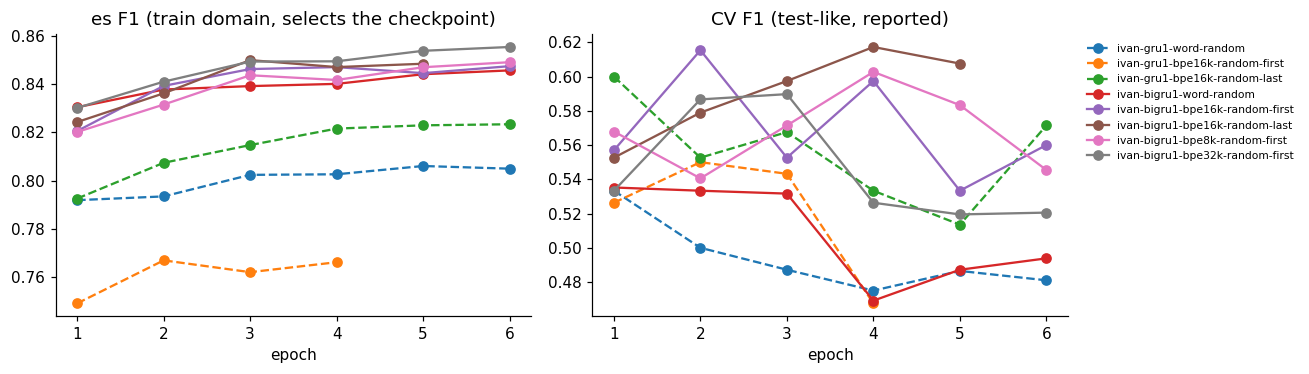

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for run in results.index:
    log = pd.read_csv(ARTIFACTS / run / "logs" / "metrics.csv")
    epochs = log.dropna(subset=["es_f1"]).groupby("epoch")[["es_f1", "cv_f1"]].last()
    style = "-" if results.loc[run, "direction"] == "bi" else "--"
    axes[0].plot(epochs.index + 1, epochs.es_f1, style, marker="o", label=run)
    axes[1].plot(epochs.index + 1, epochs.cv_f1, style, marker="o", label=run)
axes[0].set(title="es F1 (train domain, selects the checkpoint)", xlabel="epoch")
axes[1].set(title="CV F1 (test-like, reported)", xlabel="epoch")
axes[1].legend(frameon=False, fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Which gold locations does BPE find that word-level misses, and the other way round? Both runs use the BiGRU with
first-piece labels. The last column marks gold locations containing a word that is `<unk>` for the word vocabulary,
which is where BPE should help.

In [ ]:
WORD_RUN, BPE_RUN = "ivan-bigru1-word-random", "ivan-bigru1-bpe16k-random-first"
norm = lambda xs: {hard_processing(x) for x in xs}
preds = {run: decode(corpora["cv"], load_probs(run, "cv")) for run in (WORD_RUN, BPE_RUN)}
rows = []
for k, gold in enumerate(corpora["cv"].gold):
    found_word, found_bpe = norm(preds[WORD_RUN][k]), norm(preds[BPE_RUN][k])
    for g in sorted(set(gold)):
        if (hard_processing(g) in found_word) != (hard_processing(g) in found_bpe):
            rows.append({"gold location": g, "word-level": hard_processing(g) in found_word,
                         "BPE 16k": hard_processing(g) in found_bpe,
                         "has a word-level <unk>": any(t.text.lower() not in word_vocab.stoi for t in word_tokenize(g))})
pd.DataFrame(rows)

,gold location,word-level,BPE 16k,has a word-level <unk>
0,Бориспіль,False,True,False
1,ТЦ Аркадія,False,True,False
2,Бучанском,True,False,True
3,Фастовском,True,False,True
4,"вул. Солом'янська, 28",False,True,True


## 6. Conclusions

`best_epoch` in the table counts from 0, so 5 means the 6th epoch.

1. **BPE beats word-level in every pairing.** With the same model, the CV F1 rises from 0.486 to 0.550–0.571 for the
   GRU and from 0.494 to 0.560–0.597 for the BiGRU. All six BPE runs (0.52–0.60) score above both word-level runs
   (0.49), and partial-match F1 rises with them. One run alone would be inside the CV noise (±0.16), but six out of six
   is a pattern. The BPE 16k models are also 2.6× smaller (2.6M vs 7.0M parameters), because the embedding table has
   16k rows instead of 50k.
2. **The best setup is BiGRU + BPE 16k + label on the last piece: CV 0.597** (precision 0.51, recall 0.72), against
   0.488 for the vanilla RNN baseline. It is not yet confirmed on the LB.
3. **Label on the last piece beats the first piece**, as expected:
   - **GRU:** es F1 0.767 → 0.823 and CV 0.550 → 0.571. With the first piece, a one-direction model must tag `Васильковом`
     after reading only `василь`. With the last piece it has read the whole word. This explains the failure of the
     first BPE attempt (CV 0.411).
   - **BiGRU:** es is the same (0.847 vs 0.850), because the backward pass already shows the whole word to the first
     piece. CV still prefers the last piece (0.560 → 0.597), but that gap is within the noise.
4. **Bidirectional helps on es more than on CV.** Word-level es F1 rises from 0.806 to 0.846, but CV only from 0.486 to
   0.494. On test-like posts the tokenizer matters more than the direction.
5. **BPE size: 16k is the sweet spot on CV** (8k 0.545, 16k 0.560, 32k 0.521, all with first-piece labels), while es
   rises slightly with size (0.849 → 0.855). A bigger vocabulary keeps more whole words, which helps on train-like text
   but leaves rare names split into fewer, rarer pieces, closer to word-level behaviour. The differences are small
   against the noise, so 16k is a reasonable default rather than a proven optimum.
6. **es and CV disagree again.** es rises steadily, so most runs train to epoch 6, while CV peaks around epochs 2–3 and
   then wanders. This is the same domain gap as in notebook 02: the checkpoint chosen on es is not the best one for
   test-like posts.
7. **What BPE finds and misses.** Against the word-level BiGRU, BPE finds `Бориспіль`, `ТЦ Аркадія` and
   `вул. Солом'янська, 28` (`Солом'янська` is `<unk>` for word-level). It loses the Russian forms `Фастовском` and
   `Бучанском`, which the word-level model tagged from context (`в X и Y районах`). The rest of the gain is fewer false
   positives: precision rises from 0.41 to 0.49–0.51.
8. **Cost:** sequences are 1.3–1.6× longer, and so is an epoch (BiGRU: 3.2 min per epoch word-level, 4.0–4.9 min BPE).

**Recommendations for the team:**
- Use **BPE 16k with last-piece labels** as the default tokenizer for architecture and optimizer experiments (points 3
  and 4). Every model still outputs word-level probabilities, so the ensemble can mix word-level and BPE models.
- fastText vectors (point 6) exist for whole words, so the fastText runs stay word-level. That is fine: a word-level
  fastText model and a BPE model make different mistakes, which is what an ensemble needs.
- Submit `ivan-bigru1-bpe16k-random-last` to confirm the gain on the LB.

## 7. Submit (optional)
Set `SUBMIT_RUN` to a run name to send its `submission.csv` to Kaggle (10 submissions a day for the team).
Then write the public LB score into the results log.

In [ ]:
SUBMIT_RUN = None
if SUBMIT_RUN:
    subprocess.run(["kaggle", "competitions", "submit", "-c", COMPETITION, "-f",
                    str(ARTIFACTS / SUBMIT_RUN / "submission.csv"), "-m", SUBMIT_RUN], check=True)